In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

In [53]:
# Data downloaded from https://agsi.gie.eu/data-overview/EU

ng_filepath = '../../data/Natural_Gas_data/StorageData_GIE_2020-01-01_2026-06-03.csv'
filepath = '../../data/Natural_Gas_data/StorageData_GIE_2020-01-01_2026-06-03.json'

In [54]:
df_cols = pd.read_csv(ng_filepath, sep='";"')
df_cols.columns = df_cols.columns.str.strip('"')
cols = df_cols.columns.to_list()
cols.remove('Status;""Gas Day Start (status at 6AM  CEST)')
new_cols = ['Status', 'Gas Day Start']
new_cols += cols
new_cols

/tmp/ipykernel_1094871/1006445271.py:1: ParserWarning: Falling back to the 'python' engine because the 'c' engine does not support regex separators (separators > 1 char and different from '\s+' are interpreted as regex); you can avoid this warning by specifying engine='python'.
  df_cols = pd.read_csv(ng_filepath, sep='";"')


['Status',
 'Gas Day Start',
 'Gas Day End',
 'Gas in storage (TWh)',
 'Full (%)',
 'Trend (%)',
 'Injection (GWh/d)',
 'Withdrawal (GWh/d)',
 'Technical Capacity (TWh)',
 'Injection capacity (GWh/d)',
 'Withdrawal capacity (GWh/d)',
 'Contracted Capacity (TWh)',
 'Available Capacity (TWh)']

In [61]:
file2 = '../../data/Natural_Gas_data/StorageData_GIE_2015-01-01_2022-10-06.json'

df_full = pd.read_json(file2) #full available time period

df_full.columns = new_cols

df_full['Gas Day Start'] = pd.to_datetime(df_full['Gas Day Start'], format='%Y-%m-%d')
df_full['year_month'] = pd.to_datetime(df_full['Gas Day Start']).dt.to_period('M').astype(str)

Text(0, 0.5, 'Frequency')

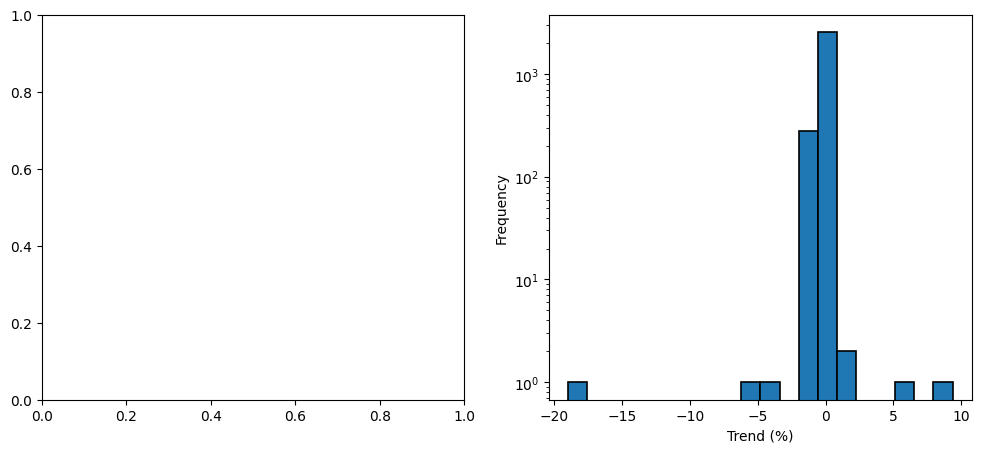

In [69]:
fig, axs = plt.subplots(1, 2, figsize=(12, 5))

# axs[0].plot(df_full['Gas Day Start'], df_full['Trend (%)'], label='Trend')
# axs[0].set_xlabel('Gas Day Start')
# axs[0].set_ylabel('Trend (%)')
# axs[0].set_xticks(df_full['year_month'])  # Show every 10th month for readability
# axs[0].set_title('Trend Over Time')
# axs[0].legend()

axs[1].hist(df_full['Trend (%)'], bins=20, alpha=1, edgecolor='black', linewidth=1.2)
axs[1].set_xlabel('Trend (%)')
axs[1].set_yscale('log')  # Set y-axis to logarithmic scale
axs[1].set_ylabel('Frequency')


In [ ]:
df['Gas Day Start'] = pd.to_datetime(df['Gas Day Start'], format='%Y-%m-%d')


,Status,Gas Day Start,Gas Day End,Gas in storage (TWh),Full (%),Trend (%),Injection (GWh/d),Withdrawal (GWh/d),Technical Capacity (TWh),Injection capacity (GWh/d),Withdrawal capacity (GWh/d),Contracted Capacity (TWh),Available Capacity (TWh),Phase
0,C,2026-06-03,2026-06-04,466.7651,41.25,0.23,3034.39,492.1,1131.4660,12236.89,20011.71,1007.5989,122.6223,1
1,C,2026-06-02,2026-06-03,464.2190,41.03,0.27,3308.68,311.9,1131.4660,12248.40,20044.75,1007.5992,122.6221,1
2,C,2026-06-01,2026-06-02,461.2166,40.76,0.28,3469.56,299.9,1131.4660,12248.95,20043.79,1007.6519,122.5693,1
3,E,2026-05-31,2026-06-01,457.9923,40.48,0.39,4323.16,66.3,1131.4655,12249.40,20043.00,1010.3684,125.6661,1
4,C,2026-05-30,2026-05-31,453.6316,40.09,0.36,4115.16,95.7,1131.4655,12249.66,20042.55,1010.3655,125.6690,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2341,E,2020-01-05,2020-01-06,976.4430,86.42,-0.39,281.67,4717.6,1129.8998,11865.01,20519.76,0.0000,0.0000,0
2342,E,2020-01-04,2020-01-05,980.9061,86.81,-0.37,315.24,4588.3,1129.8998,11864.75,20520.44,0.0000,0.0000,0
2343,E,2020-01-03,2020-01-04,985.1282,87.19,-0.40,321.83,4808.1,1129.8998,11864.31,20521.61,0.0000,0.0000,0
2344,E,2020-01-02,2020-01-03,989.6235,87.59,-0.47,325.91,5797.1,1129.8998,11863.84,20522.86,0.0000,0.0000,0


In [ ]:
url = 'https://agsi.gie.eu/data-overview/EU'
data =